[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/course-2026A-5.5.0/curso/notebooks/T05_G_choques_narrativos_llm_banxico_es.ipynb)

> **Nota para Google Colab**: la celda siguiente instala `puremacro` y, si hace falta, descarga del repositorio público [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro) sólo la carpeta `curso/notebooks` de la edición `course-2026A-5.5.0` (auxiliares, datos congelados y modelos). No pide acceso a Google Drive.

In [1]:
# Configuración: Google Colab, Python local o Juno (iPad)
import os
import sys
import subprocess
from pathlib import Path

_course_requirements = ['puremacro==5.5.0']
_course_edition = 'course-2026A-5.5.0'

def _safe_probe(p, is_dir=None):
    """Test paths without raising in the Juno sandbox."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_course_requirements], check=True)
    # A separate directory per edition prevents reuse of helpers from another course.
    _repo = Path("/content/puremacro-" + _course_edition)
    if not _safe_probe(_repo, is_dir=True):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                        "--branch", _course_edition, "https://github.com/jalonso1979/puremacro.git", str(_repo)], check=True)
    subprocess.run(["git", "-C", str(_repo), "checkout", "--detach", _course_edition], check=True)
    subprocess.run(["git", "-C", str(_repo), "sparse-checkout", "set", "curso/notebooks"], check=True)
    _course_status = subprocess.run(["git", "-C", str(_repo), "status", "--porcelain",
                                     "--untracked-files=normal", "--", "curso/notebooks"],
                                    check=True, capture_output=True, text=True).stdout
    if _course_status.strip():
        raise RuntimeError("The cached course edition was modified; use a fresh Colab runtime for the frozen edition.")
    os.chdir(_repo / "curso/notebooks")

# Locate the course helpers for local Python, Colab and Juno.
_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidates.insert(0, Path(__file__).resolve().parent)
except (NameError, OSError):
    pass
for _c in _candidates:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

import puremacro
if puremacro.__version__ != "5.5.0":
    raise RuntimeError("This course edition requires puremacro==5.5.0; install it and restart the kernel.")

# Cached reference responses are the reproducible default; live models are optional.
os.environ.setdefault("MAV_LLM_MODE", "cache")

%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

Matplotlib is building the font cache; this may take a moment.


# Tema 5 — Choques monetarios narrativos con un modelo de lenguaje local: Banxico y la Reserva Federal

**Macroeconomía Avanzada · Maestría en Economía (MAV) · Laboratorio Semana 10**

En el Tema 1 (`T01_C`) estimamos el efecto causal dinámico de la política monetaria en México mediante proyecciones locales de Jordà (2005) con variables instrumentales (`lp_iv`), instrumentando la tasa interbancaria a 3 meses (`TIIE`) con el indicador codificado a mano de las decisiones del Banco de México (`banxico_direction`). En el Tema 3 (`T03_F`) medimos el tono de la banca central con diccionarios léxicos y similitud coseno TF-IDF.

En este laboratorio unimos ambos bloques: empleamos el **modelo de lenguaje local de 4 mil millones de parámetros (`qwen3-4b`)** mediante `puremacro.narrative.score_llm(..., kind="monetary")` para extraer eventos estructurados de política monetaria (`policy_rate`, `forward_guidance`, `asset_purchase`) de los corpus completos 2008–2026 de comunicados de decisión del **Banco de México (`banxico_comunicados.csv`)** y del **Comité Federal de Mercado Abierto (`fomc_statements.csv`)**, validamos la serie extraída frente al registro codificado a mano y la contrastamos como instrumento externo en `lp_iv`.

## 1. Configuración y corpus de comunicados de bancos centrales

Inicializamos el ayudante del modelo local del curso `_llm.get_llm(lang="es")` (que lee de forma determinista `data_curso/llm_cache.sqlite` en modo `cache`, sin llave de API ni conexión a la red) e inspeccionamos los dos corpus congelados de comunicados construidos con `scripts/construir_corpus_bancos_centrales.py`.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import _nbstyle
import _llm
from _datos import DATOS, ruta_dato
from puremacro.narrative.scoring.llm import _build_prompt, score_llm
from puremacro.lp import lp_iv
from puremacro.regress import ols, add_constant

_nbstyle.apply_style()
llm = _llm.get_llm(lang="es")
print(llm.report())

df_bx = pd.read_csv(ruta_dato("bancos_centrales/banxico_comunicados.csv"))
df_fed = pd.read_csv(ruta_dato("bancos_centrales/fomc_statements.csv"))

for etiqueta, df in [("Banxico (ES)", df_bx), ("FOMC (EN)", df_fed)]:
    wc = df["text"].str.split().str.len()
    q10, q50, q90 = wc.quantile([0.10, 0.50, 0.90])
    print(f"\n{etiqueta}: {len(df)} comunicados ({df['date'].min()} a {df['date'].max()})")
    print(f"  Percentiles de longitud (palabras) — p10: {q10:.0f}, mediana: {q50:.0f}, p90: {q90:.0f}")

Modelo local del curso
  modo:     cache (sólo la caché del curso; sin motores ni red)
  modelo:   qwen3-4b
  caché:    T05_G_choques_narrativos_llm_banxico_es/llm-user.sqlite (0 filas; el archivo todavía no existe)
  backend:  puremacro.llm (puremacro 5.5.0)

Banxico (ES): 161 comunicados (2008-01-18 a 2026-09-24)
  Percentiles de longitud (palabras) — p10: 519, mediana: 1000, p90: 1556

FOMC (EN): 161 comunicados (2008-01-22 a 2026-09-16)
  Percentiles de longitud (palabras) — p10: 252, mediana: 441, p90: 655


## 2. El texto: lectura de los comunicados de decisión

¿Por qué acudieron Romer y Romer (1989, 2004) a los documentos narrativos de la banca central? Porque el cambio observado en la tasa de referencia $\Delta i_t$ combina dos componentes económicamente distintos:
$$\Delta i_t = \underbrace{f(\Omega_t)}_{\text{reacción endógena a actividad e inflación}} + \underbrace{\varepsilon_t^m}_{\text{choque de política monetaria}}$$
Cuando el banco central sube la tasa porque observa presiones inflacionarias en $\Omega_t$, una regresión por MCO de la inflación futura $\pi_{t+h}$ sobre $\Delta i_t$ padece sesgo de simultaneidad positivo (el **enigma de precios** o *price puzzle*). Los comunicados oficiales documentan tanto la acción discreta sobre la tasa (`policy_rate`) como la guía prospectiva y el balance de riesgos (`forward_guidance`). A continuación inspeccionamos el recorte de 1 500 palabras (`excerpt`) que recibe el modelo local en dos decisiones clave de despegue restrictivo: el alza sorpresa de Banxico en junio de 2021 y el despegue del FOMC en marzo de 2022, nueve meses después.

In [3]:
row_bx_sample = df_bx.loc[df_bx["date"] == "2021-06-24"].iloc[0]
row_fed_sample = df_fed.loc[df_fed["date"] == "2022-03-16"].iloc[0]

print(f"=== Comunicado de Banxico ({row_bx_sample['date']}) — {len(row_bx_sample['excerpt'].split())} palabras en excerpt ===")
print(row_bx_sample["excerpt"][:520] + " ...\n")

print(f"=== Comunicado del FOMC ({row_fed_sample['date']}) — {len(row_fed_sample['excerpt'].split())} palabras en excerpt ===")
print(row_fed_sample["excerpt"][:520] + " ...")

=== Comunicado de Banxico (2021-06-24) — 758 palabras en excerpt ===
El objetivo para la Tasa de Interés Interbancaria a 1 día (tasa objetivo) se incrementa en 25 puntos base Anuncio de Política Monetaria Comunicado de Prensa 24 de junio de 2021 La Junta de Gobierno del Banco de México decidió incrementar en 25 puntos base el objetivo para la Tasa de Interés Interbancaria a un día a un nivel de 4.25%, con efectos a partir del 25 de junio de 2021. La recuperación de la actividad económica global mostró un repunte durante el segundo trimestre del año, con heterogeneidad entre países p ...

=== Comunicado del FOMC (2022-03-16) — 369 palabras en excerpt ===
March 16, 2022 Federal Reserve issues FOMC statement For release at 2:00 p.m. EDT Share Indicators of economic activity and employment have continued to strengthen. Job gains have been strong in recent months, and the unemployment rate has declined substantially. Inflation remains elevated, reflecting supply and demand imbalances relate

## 3. Extracción estructurada con `score_llm` (`kind="monetary"`)

En lugar de contar palabras aisladas, `score_llm(..., kind="monetary")` pide al modelo de lenguaje transformar cada comunicado en un arreglo JSON de eventos estructurados de política monetaria:
- `target`: `"policy_rate"`, `"forward_guidance"`, `"asset_purchase"`, `"fx_intervention"` o `"lending_facility"`
- `sign`: $+1$ (restrictivo / *hawkish*), $0$ (neutral / pausa) o $-1$ (acomodaticio / *dovish*)
- `magnitude_bps`: ajuste de la tasa objetivo en puntos base ($0$ cuando no se declara o es guía prospectiva)
- `confidence`: confianza del modelo en $[0, 1]$
- `excerpt`: la oración textual del comunicado que sustenta el evento

Tras extraer los eventos de ambos corpus, imprimimos una muestra determinista de 10 filas para auditar a mano la calidad de la extracción frente al texto fuente antes de pasar a la econometría.

In [4]:
bx_records = list(zip(df_bx["date"], df_bx["excerpt"], df_bx["url"]))
fed_records = list(zip(df_fed["date"], df_fed["excerpt"], df_fed["url"]))

events_bx = score_llm(bx_records, kind="monetary", backend=llm.backend(), language="es", country="MEX")
events_fed = score_llm(fed_records, kind="monetary", backend=llm.backend(), language="en", country="USA")

def _events_to_df(events):
    rows = []
    for e in events:
        prob = 0.50 + 0.35 * e.sign if e.sign != 0 else 0.50
        rows.append({
            "date": pd.Timestamp(e.date),
            "target": e.target,
            "sign": int(e.sign),
            "magnitude_bps": float(e.magnitude),
            "hawkish_dovish_prob": round(prob, 2),
            "confidence": float(e.confidence),
            "excerpt": str(e.source_text),
        })
    return pd.DataFrame(rows)

df_ev_bx = _events_to_df(events_bx)
df_ev_fed = _events_to_df(events_fed)

print(f"Eventos extraídos de Banxico: {len(df_ev_bx)} en {len(df_bx)} comunicados")
print(df_ev_bx.groupby(["target", "sign"]).size().unstack(fill_value=0))
print(f"\nEventos extraídos del FOMC:   {len(df_ev_fed)} en {len(df_fed)} comunicados")
print(df_ev_fed.groupby(["target", "sign"]).size().unstack(fill_value=0))

# Auditoría manual: 10 eventos muestreados con semilla fija junto a su oración fuente
rng = np.random.default_rng(2026)
spot_idx = sorted(rng.choice(len(df_ev_bx), size=10, replace=False))
print("\n=== Auditoría manual: 10 eventos muestreados de Banxico ===")
for idx in spot_idx:
    r = df_ev_bx.iloc[idx]
    print(f"{r['date']:%Y-%m-%d} | {r['target']:<16s} | sign={r['sign']:+d} | "
          f"bps={r['magnitude_bps']:5.1f} | conf={r['confidence']:.2f} | {r['excerpt'][:85]}")

Eventos extraídos de Banxico: 171 en 161 comunicados
sign              -1   0   1
target                      
forward_guidance   3   0   7
policy_rate       38  90  33

Eventos extraídos del FOMC:   172 en 161 comunicados
sign              -1    0   1
target                       
asset_purchase     4    0   4
forward_guidance   0    0   3
policy_rate       22  107  32

=== Auditoría manual: 10 eventos muestreados de Banxico ===
2008-05-16 | policy_rate      | sign=+0 | bps=  0.0 | conf=0.90 | La Junta de Gobierno del Banco de México ha d ecidido mantener en 7.5 por ciento el o
2009-03-20 | policy_rate      | sign=-1 | bps= 75.0 | conf=0.94 | La Junta de Gobierno del Banco de Mé xico ha decidido reducir en 75 puntos base el ob
2010-08-20 | policy_rate      | sign=+0 | bps=  0.0 | conf=0.90 | La Junta de Gobierno del Banco de México ha decidido mantener en 4.5 por ciento el
2014-03-21 | policy_rate      | sign=+0 | bps=  0.0 | conf=0.90 | La Junta de Gobierno del Banco de México ha dec

## 4. De los eventos por reunión a una serie mensual de postura

Para combinar los eventos por reunión con paneles macroeconómicos mensuales, asignamos cada evento a su mes calendario ($t$), ponderamos su signo por la confianza del modelo ($s_{i,t} = \text{sign}_{i,t} \times \text{confidence}_{i,t}$) y sumamos dentro de cada mes (asignando $0$ a los meses sin anuncio).

Validamos la dirección mensual extraída por el modelo ($\text{sign}(\sum_i s_{i,t}) \in \{-1, 0, +1\}$) frente a:
1. **Banco de México**: la serie codificada a mano `banxico_direction` en `banxico_stance_monthly.csv` (220 meses, 2008–2026), reportando la matriz de confusión $3 \times 3$ e imprimiendo la oración del comunicado en cada mes donde ambas series discrepan.
2. **Reserva Federal**: las variaciones mensuales de la tasa efectiva de fondos federales (`FEDFUNDS.csv`).

In [5]:
df_ev_bx["weighted"] = df_ev_bx["sign"] * df_ev_bx["confidence"]
df_ev_bx["month"] = df_ev_bx["date"].dt.to_period("M").dt.to_timestamp()
bx_llm_m = df_ev_bx.groupby("month").agg(
    llm_stance=("weighted", "sum"),
    llm_dir=("weighted", lambda s: int(np.sign(s.sum()))),
    excerpt=("excerpt", "last"),
)

bx_m = pd.read_csv(ruta_dato("banxico_stance_monthly.csv"), parse_dates=["date"]).rename(columns={"date": "month"})
val_bx = bx_m[bx_m["month"] >= "2008-01-01"].merge(bx_llm_m, on="month", how="left")
val_bx["llm_stance"] = val_bx["llm_stance"].fillna(0.0)
val_bx["llm_dir"] = val_bx["llm_dir"].fillna(0).astype(int)
val_bx["banxico_direction"] = val_bx["banxico_direction"].astype(int)

cm_bx = pd.crosstab(val_bx["banxico_direction"], val_bx["llm_dir"],
                    rownames=["Codificado"], colnames=["Dirección LLM"])
agree_bx = float((val_bx["banxico_direction"] == val_bx["llm_dir"]).mean())
print(f"Tasa de coincidencia mensual en Banxico (2008-2026, N={len(val_bx)}): {agree_bx:.1%}\n")
print(cm_bx)

dis_bx = val_bx[val_bx["banxico_direction"] != val_bx["llm_dir"]]
print(f"\nMeses donde la postura LLM difiere de la acción en tasa ({len(dis_bx)} meses):")
for _, r in dis_bx.iterrows():
    print(f"  {r['month']:%Y-%m}: codificado={r['banxico_direction']:+d}, llm={r['llm_dir']:+d} | {str(r['excerpt'])[:92]}")

# Agregación mensual del FOMC y validación frente a FEDFUNDS.csv
df_ev_fed["weighted"] = df_ev_fed["sign"] * df_ev_fed["confidence"]
df_ev_fed["month"] = df_ev_fed["date"].dt.to_period("M").dt.to_timestamp()
fed_llm_m = df_ev_fed.groupby("month").agg(
    fed_llm_stance=("weighted", "sum"),
    fed_llm_dir=("weighted", lambda s: int(np.sign(s.sum()))),
)
ff = pd.read_csv(ruta_dato("FEDFUNDS.csv"))
ff["month"] = pd.to_datetime(ff.iloc[:, 0])
ff["fedfunds"] = pd.to_numeric(ff.iloc[:, 1], errors="coerce")
ff["d_ff"] = ff["fedfunds"].diff()
ff["ff_dir"] = np.where(ff["d_ff"] >= 0.12, 1, np.where(ff["d_ff"] <= -0.12, -1, 0))
val_fed = ff[(ff["month"] >= "2008-01-01") & (ff["month"] <= "2026-06-01")].merge(fed_llm_m, on="month", how="left")
val_fed["fed_llm_stance"] = val_fed["fed_llm_stance"].fillna(0.0)
val_fed["fed_llm_dir"] = val_fed["fed_llm_dir"].fillna(0).astype(int)
corr_fed = val_fed["fed_llm_stance"].corr(val_fed["d_ff"])
print(f"\nValidación FOMC (2008-2026, N={len(val_fed)}): corr(postura LLM, d_FEDFUNDS) = {corr_fed:.3f}")

Tasa de coincidencia mensual en Banxico (2008-2026, N=220): 95.5%

Dirección LLM  -1    0   1
Codificado                
-1             37    0   0
 0              3  140   7
 1              0    0  33

Meses donde la postura LLM difiere de la acción en tasa (10 meses):
  2011-03: codificado=+0, llm=+1 | La Junta de Gobierno vigilará estrechamente el comportamiento de los determinantes de la inf
  2013-01: codificado=+0, llm=-1 | En caso de que dicha tendencia continúe, podría resultar conveniente una reducción en el obj
  2015-10: codificado=+0, llm=+1 | La Junta se mantendrá atenta a la postura monetaria relativa entre México y Estados Unidos c
  2017-08: codificado=+0, llm=+1 | El balance de riesgos para la inflación se mantiene sesgado al alza en un entorno de alta in
  2018-04: codificado=+0, llm=+1 | La Junta de Gobierno dará seguimiento cercano al traspaso potencial de las variaciones del t
  2018-08: codificado=+0, llm=+1 | Ante la presencia de factores que pudieran obstaculiza

## 5. Comparación de ciclos monetarios: Banxico frente a la Reserva Federal

Al graficar la suma móvil de 12 meses de la postura monetaria extraída por el modelo para Banxico y el FOMC destacan cuatro episodios entre 2008 y 2026:
1. **Crisis Financiera Global (2008–2009)**: Recortes sincronizados en ambos bancos centrales.
2. ***Taper Tantrum* (2013)**: El FOMC anuncia la moderación de compras de activos (`forward_guidance` / `asset_purchase` con signo $+1$) mientras Banxico recorta su tasa ante la holgura interna.
3. **Pandemia de COVID-19 (2020)**: Relajamiento inmediato del FOMC a la cota cero junto con compras masivas de activos, mientras Banxico ejecuta recortes escalonados de 50 pb.
4. **Choque inflacionario pospandemia (2021–2022)**: Banxico inicia su ciclo de alzas en junio de 2021 —nueve meses antes del despegue del FOMC en marzo de 2022— para anclar las expectativas de inflación.

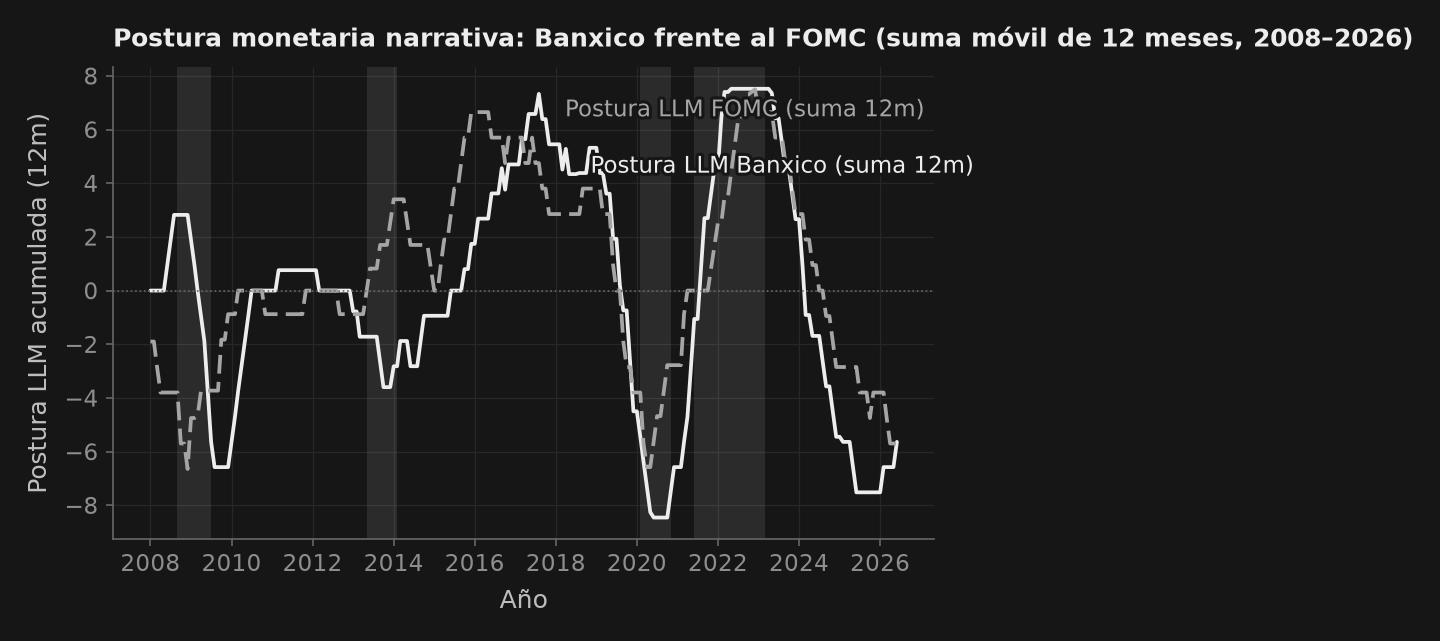

In [6]:
panel_m = pd.date_range("2008-01-01", "2026-06-01", freq="MS")
comp_m = pd.DataFrame(index=panel_m)
comp_m["bx_stance"] = bx_llm_m["llm_stance"].reindex(panel_m).fillna(0.0)
comp_m["fed_stance"] = fed_llm_m["fed_llm_stance"].reindex(panel_m).fillna(0.0)
comp_m["bx_roll12"] = comp_m["bx_stance"].rolling(12, min_periods=1).sum()
comp_m["fed_roll12"] = comp_m["fed_stance"].rolling(12, min_periods=1).sum()

fig, ax = _nbstyle.figura(1, 1, figsize=plt.rcParams["figure.figsize"])
ax.plot(comp_m.index, comp_m["bx_roll12"], color=_nbstyle.S1["color"], ls="-", lw=1.8,
        label="Postura LLM Banxico (suma 12m)")
ax.plot(comp_m.index, comp_m["fed_roll12"], color=_nbstyle.S2["color"], ls=_nbstyle.S2["linestyle"], lw=1.8,
        label="Postura LLM FOMC (suma 12m)")
ax.axhline(0, color=_nbstyle.SPINE, lw=0.8, ls=":")

episodes = [
    ("2008-09-01", "2009-07-01", "2008 CFG"),
    ("2013-05-01", "2014-02-01", "2013 Taper"),
    ("2020-02-01", "2020-11-01", "2020 COVID"),
    ("2021-06-01", "2023-03-01", "2021-22 Alzas"),
]
for s_dt, e_dt, lbl in episodes:
    ax.axvspan(pd.Timestamp(s_dt), pd.Timestamp(e_dt), color=_nbstyle.RECESION, lw=0)

ax.set_title("Postura monetaria narrativa: Banxico frente al FOMC (suma móvil de 12 meses, 2008–2026)")
ax.set_ylabel("Postura LLM acumulada (12m)")
ax.set_xlabel("Año")
_nbstyle.etiquetar(ax)
plt.show()

## 6. Identificación: proyecciones locales con variables instrumentales (LP-IV) en México

Reestimamos ahora la especificación de proyecciones locales con variables instrumentales (`lp_iv`) de `T01_C` para México en los horizontes $h = 0, 1, \dots, 36$ meses:
$$y_{t+h} - y_{t-1} = \alpha_h + \beta_h \widehat{\Delta i_t} + \sum_{\ell=1}^{12} \Gamma_{h,\ell} W_{t-\ell} + u_{t+h}$$
donde $\Delta i_t$ es el cambio mensual en la tasa interbancaria a 3 meses (`IR3TIB01MXM156N.csv`), $y_t$ es $100 \times \log(\text{Producción Industrial})$ (`oecd_mei_mex_log_ip.csv`) o la inflación general anual (`CPALTT01MXM659N.csv`), y $W_t$ controla por 12 rezagos de inflación (o crecimiento industrial) y el logaritmo del índice de incertidumbre de política económica (`epu_mex_mensual.csv`). Comparamos dos instrumentos $z_t$ lado a lado:
1. **`banxico_direction` codificado a mano** ($z_t \in \{-1, 0, +1\}$, la referencia de `T01_C`).
2. **Postura monetaria del modelo `llm_stance`** ($z_t = \sum_i \text{sign}_{i,t} \times \text{confidence}_{i,t}$).

Muestra de estimación LP-IV: 2008-02 a 2023-02 (T = 181 meses)
Estadístico F primera etapa (Producción industrial) — Codificado: 17.63 | LLM: 13.62
Estadístico F primera etapa (Inflación general)     — Codificado: 15.59 | LLM: 12.34
Respuesta de PI en h=12 (100*log pts)               — Codificado:  +3.09 | LLM: +12.99
Respuesta de inflación en h=12 (pp)                 — Codificado:  +5.16 | LLM:  +7.05


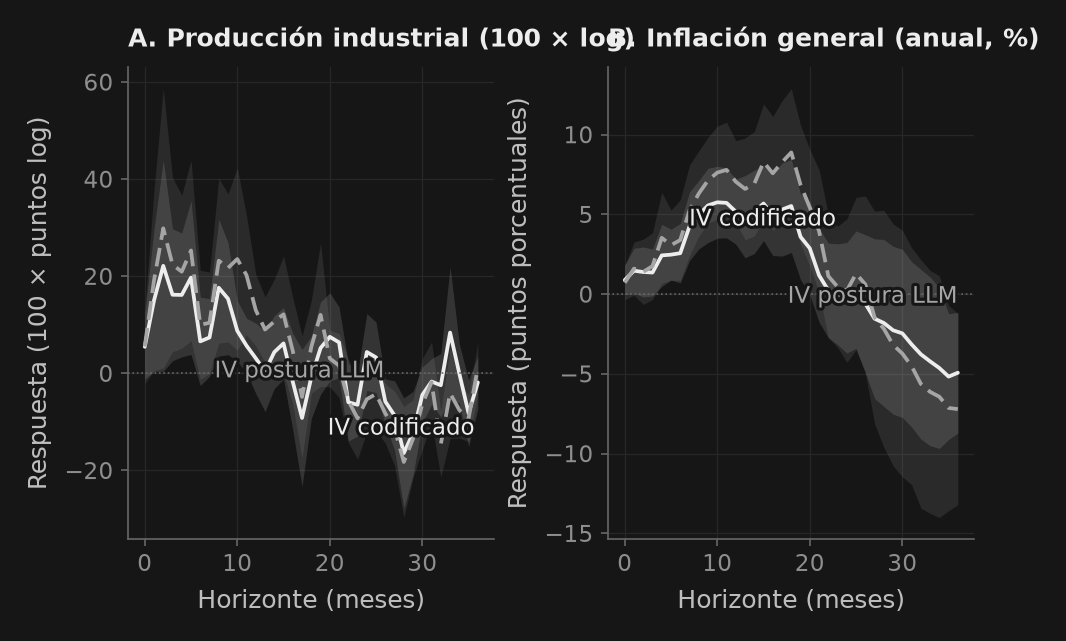

In [7]:
def _fred_monthly(sid):
    s = pd.read_csv(ruta_dato(f"{sid}.csv"))
    c0, c1 = s.columns[:2]
    s[c0] = pd.to_datetime(s[c0])
    s[c1] = pd.to_numeric(s[c1], errors="coerce")
    return s.dropna().set_index(c0)[c1].resample("MS").mean()

ip_s = pd.read_csv(ruta_dato("oecd_mei_mex_log_ip.csv"), parse_dates=["date"]).set_index("date")["log_ip_x100"]
epu_s = pd.read_csv(ruta_dato("epu_mex_mensual.csv"), parse_dates=["date"]).set_index("date")["epu"]

d_lp = pd.DataFrame({
    "i": _fred_monthly("IR3TIB01MXM156N"),
    "pi": _fred_monthly("CPALTT01MXM659N"),
    "lip": ip_s,
    "lepu": np.log(epu_s),
}).dropna()
d_lp = d_lp.join(val_bx.set_index("month")[["banxico_direction", "llm_stance"]], how="inner")
d_lp["di"] = d_lp["i"].diff()
d_lp["dlip"] = d_lp["lip"].diff()
d_lp = d_lp.dropna()

horizons = range(0, 37)
irf_ip_coded = lp_iv(d_lp, y="lip", x="di", z="banxico_direction", horizons=horizons, n_lags=12, controls=["pi", "lepu"])
irf_ip_llm   = lp_iv(d_lp, y="lip", x="di", z="llm_stance",        horizons=horizons, n_lags=12, controls=["pi", "lepu"])
irf_pi_coded = lp_iv(d_lp, y="pi",  x="di", z="banxico_direction", horizons=horizons, n_lags=12, controls=["dlip", "lepu"])
irf_pi_llm   = lp_iv(d_lp, y="pi",  x="di", z="llm_stance",        horizons=horizons, n_lags=12, controls=["dlip", "lepu"])

f_ip_coded = float(irf_ip_coded.first_stage_f.iloc[0])
f_ip_llm   = float(irf_ip_llm.first_stage_f.iloc[0])
f_pi_coded = float(irf_pi_coded.first_stage_f.iloc[0])
f_pi_llm   = float(irf_pi_llm.first_stage_f.iloc[0])

print(f"Muestra de estimación LP-IV: {d_lp.index.min():%Y-%m} a {d_lp.index.max():%Y-%m} (T = {len(d_lp)} meses)")
print(f"Estadístico F primera etapa (Producción industrial) — Codificado: {f_ip_coded:5.2f} | LLM: {f_ip_llm:5.2f}")
print(f"Estadístico F primera etapa (Inflación general)     — Codificado: {f_pi_coded:5.2f} | LLM: {f_pi_llm:5.2f}")
print(f"Respuesta de PI en h=12 (100*log pts)               — Codificado: {float(irf_ip_coded.beta[12]):+6.2f} | LLM: {float(irf_ip_llm.beta[12]):+6.2f}")
print(f"Respuesta de inflación en h=12 (pp)                 — Codificado: {float(irf_pi_coded.beta[12]):+6.2f} | LLM: {float(irf_pi_llm.beta[12]):+6.2f}")

fig, (ax1, ax2) = _nbstyle.figura(1, 2, figsize=plt.rcParams["figure.figsize"])
h_arr = np.asarray(list(horizons))

for ax, res_c, res_l, ttl, ylab in [
    (ax1, irf_ip_coded, irf_ip_llm, "A. Producción industrial (100 × log)", "Respuesta (100 × puntos log)"),
    (ax2, irf_pi_coded, irf_pi_llm, "B. Inflación general (anual, %)", "Respuesta (puntos porcentuales)"),
]:
    b_c, se_c = np.asarray(res_c.beta, dtype=float), np.asarray(res_c.se, dtype=float)
    b_l, se_l = np.asarray(res_l.beta, dtype=float), np.asarray(res_l.se, dtype=float)
    ax.fill_between(h_arr, b_c - 1.645 * se_c, b_c + 1.645 * se_c, color=_nbstyle.S1["color"], alpha=0.14, lw=0)
    ax.fill_between(h_arr, b_l - 1.645 * se_l, b_l + 1.645 * se_l, color=_nbstyle.S2["color"], alpha=0.14, lw=0)
    ax.plot(h_arr, b_c, color=_nbstyle.S1["color"], ls="-", lw=1.8, label="IV codificado")
    ax.plot(h_arr, b_l, color=_nbstyle.S2["color"], ls=_nbstyle.S2["linestyle"], lw=1.8, label="IV postura LLM")
    ax.axhline(0, color=_nbstyle.SPINE, lw=0.8, ls=":")
    ax.set_title(ttl)
    ax.set_xlabel("Horizonte (meses)")
    ax.set_ylabel(ylab)
    _nbstyle.etiquetar(ax)

plt.show()

## 7. Crítica econométrica: por qué el tono del comunicado aún requiere controlar por pronósticos

La comparación entre ambas funciones de impulso-respuesta LP-IV deja tres lecciones centrales para la identificación macroeconómica:
1. **Relevancia frente a exogeneidad del instrumento**: Tanto `banxico_direction` ($F = 17.6$) como `llm_stance` ($F = 13.6$) superan con holgura el umbral de Stock y Yogo ($F > 10$) en la primera etapa sobre $\Delta i_t$. Sin embargo, ambos instrumentos exhiben una respuesta positiva de corto plazo en la inflación ($\hat{\beta}_{12}^{\pi} > 0$, el **enigma de precios**) y en la producción antes de moderarse hacia los 24–36 meses.
2. **La crítica de Romer y Romer (2004)**: ¿Por qué un modelo de lenguaje que lee el comunicado oficial sigue heredando endogeneidad? Porque el comunicado anuncia la **decisión total de política** $\Delta i_t = f(\Omega_t) + \varepsilon_t^m$. Cuando Banxico sube la tasa o emite guía prospectiva restrictiva (*"el balance de riesgos para la inflación se mantiene sesgado al alza"*), responde a su propio pronóstico de mayor inflación. Romer y Romer (2004) aislaron $\varepsilon_t^m$ únicamente tras regresar el cambio de tasa sobre los **pronósticos internos del *Greenbook*** de inflación y actividad real.
3. **Modos concretos de fallo en la extracción textual**: Nuestra auditoría de la Sección 4 identificó 10 meses donde `llm_stance` difiere de la acción discreta sobre la tasa, agrupados en tres patrones lingüísticos:
   - *Vigilancia condicional / lenguaje precautorio*: Comunicados que mantienen la tasa sin cambio ($0\text{ pb}$) pero advierten que *"la Junta vigilará estrechamente el traspaso del tipo de cambio"* (`2011-03`, `2015-10`, `2018-04`).
   - *Reiteración del balance de riesgos*: Énfasis en que el balance de riesgos inflacionarios continúa sesgado al alza durante una pausa restrictiva (`2017-08`, `2021-05`, `2023-05`).
   - *Votos disidentes / opiniones minoritarias*: Mención de miembros que sugerían relajar la postura mientras la mayoría mantuvo la tasa (`2019-06`).

In [8]:
# Diagnóstico: ¿qué fracción de cada instrumento es predecible a partir del estado macro rezagado?
d_diag = d_lp.copy()
d_diag["pi_lag1"] = d_diag["pi"].shift(1)
d_diag["dlip_lag1"] = d_diag["dlip"].shift(1)
d_diag["lepu_lag1"] = d_diag["lepu"].shift(1)
d_diag = d_diag.dropna()

X_state = add_constant(d_diag[["pi_lag1", "dlip_lag1", "lepu_lag1"]])
fit_coded = ols(d_diag["banxico_direction"], X_state, cov_type="HAC", cov_kwds={"maxlags": 3})
fit_llm   = ols(d_diag["llm_stance"],        X_state, cov_type="HAC", cov_kwds={"maxlags": 3})

print("Diagnóstico de endogeneidad — Predicción con variables de estado rezagadas (pi_{t-1}, dlip_{t-1}, lepu_{t-1}):")
print(f"  banxico_direction codificado: R^2 = {fit_coded.rsquared:.3f}, beta(pi_{{t-1}}) = {fit_coded.params['pi_lag1']:+.4f} (p = {fit_coded.pvalues['pi_lag1']:.3e})")
print(f"  Postura monetaria LLM:        R^2 = {fit_llm.rsquared:.3f}, beta(pi_{{t-1}}) = {fit_llm.params['pi_lag1']:+.4f} (p = {fit_llm.pvalues['pi_lag1']:.3e})")

# Aserciones de verificación
assert len(df_bx) >= 150 and len(df_fed) >= 150, "Los corpus deben cubrir 2008-2026"
assert len(df_ev_bx) >= 160 and len(df_ev_fed) >= 160, "score_llm debe extraer >=160 eventos por banco"
assert agree_bx >= 0.90, f"Se esperaba >=90% de coincidencia mensual con banxico_direction, se obtuvo {agree_bx:.3f}"
assert f_ip_coded > 10.0 and f_ip_llm > 10.0, "Ambos instrumentos deben tener F de primera etapa > 10"
assert _llm.MISSES == [], f"Se esperaban cero misses de caché en modo cache, se obtuvo {_llm.MISSES}"
print("\n✓ ¡Todas las aserciones de extracción narrativa e identificación LP-IV se cumplieron correctamente!")

Diagnóstico de endogeneidad — Predicción con variables de estado rezagadas (pi_{t-1}, dlip_{t-1}, lepu_{t-1}):
  banxico_direction codificado: R^2 = 0.127, beta(pi_{t-1}) = +0.1238 (p = 8.470e-04)
  Postura monetaria LLM:        R^2 = 0.134, beta(pi_{t-1}) = +0.1236 (p = 3.883e-04)

✓ ¡Todas las aserciones de extracción narrativa e identificación LP-IV se cumplieron correctamente!


## 8. Ejecución en vivo opcional: caché de referencia frente a tu modelo local

Todos los resultados anteriores provienen de la caché de referencia congelada (`qwen3-4b`) para que la práctica sea 100% reproducible en cualquier equipo. La siguiente celda vuelve a evaluar el comunicado de despegue de Banxico del 24 de junio de 2021 con tu motor local cuando `MAV_LLM_MODE=auto` (o lee de la caché de referencia en modo `cache`, siguiendo exactamente el patrón de `T00_B`).

In [9]:
# Compara la extracción de referencia en caché (qwen3-4b) con tu modelo local sobre un comunicado (2021-06-24).
# En modo auto, "off" ejecuta tu motor local aunque la respuesta esté en la caché;
# en modo cache no se invoca ningún motor y ambas líneas leen de la caché del curso.
prompt_2021 = _build_prompt(
    kind="monetary",
    language="es",
    country="MEX",
    date=str(row_bx_sample["date"]),
    text=str(row_bx_sample["excerpt"]),
)
ref_2021 = _llm.get_llm(mode="cache", model=_llm.REFERENCE_MODEL, lang="es").try_complete(prompt_2021, max_tokens=1024)
modo_vivo = "off" if llm.mode == "auto" else llm.mode
vivo_2021 = _llm.get_llm(mode=modo_vivo, lang="es").try_complete(prompt_2021, max_tokens=1024)
print("referencia (caché qwen3-4b):", ref_2021)
print("en vivo    (modelo local):  ", vivo_2021)

referencia (caché qwen3-4b): [{"magnitude_bps": 25.0, "target": "policy_rate", "subtarget": "tasa de interés interbancaria a un día", "sign": 1, "hawkish_dovish_prob": 0.87, "confidence": 0.94, "excerpt": "La Junta de Gobierno del Banco de México decidió incrementar en 25 puntos base el objetivo", "implementation_date": null, "horizon_quarters": null}]
en vivo    (modelo local):   [{"magnitude_bps": 25.0, "target": "policy_rate", "subtarget": "tasa de interés interbancaria a un día", "sign": 1, "hawkish_dovish_prob": 0.87, "confidence": 0.94, "excerpt": "La Junta de Gobierno del Banco de México decidió incrementar en 25 puntos base el objetivo", "implementation_date": null, "horizon_quarters": null}]


## 9. Ejercicios

1. **Separación entre acción de tasa y guía prospectiva**: Filtra `df_ev_bx` para conservar únicamente los eventos con `target == "forward_guidance"` y construye una serie mensual pura de guía prospectiva `fg_stance`. Reestima `lp_iv` usando `fg_stance` como instrumento $z_t$. ¿Tiene la guía prospectiva pura una primera etapa fuerte sobre la tasa interbancaria a 3 meses (`IR3TIB01MXM156N`)?
2. **Ortogonalización respecto al estado macroeconómico**: Utiliza el residuo $\hat{u}_t = z_t - \widehat{z}_t$ de la regresión de estado de la Sección 7 (`fit_llm.resid`) como instrumento depurado en `lp_iv`. ¿En cuánto se atenúa el enigma de precios de corto plazo al purgar la inflación y el crecimiento industrial rezagados?